# Reported accounts and emergency-money difficulty in India

Among lower-income Indian adults, how is reported financial-institution account ownership associated with severe difficulty arranging emergency money?

This analysis uses the Global Findex 2025 India public-use release, with responses collected in 2024. The survey population starts at age 15. Lower income means the bottom two within-India household-income quintiles, rather than an official poverty-line group. Those population groups need not contain exactly 40% of the unweighted sample. The severe-outcome comparison is negative after adjustment; the broader any-difficulty comparison is unclear. Both results are reported.


In [1]:
from pathlib import Path
from statistics import NormalDist
import hashlib
import json
import os
import platform

import numpy as np
import pandas as pd
import statsmodels
import statsmodels.api as sm
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
METADATA = ROOT / "results" / "metadata"
for directory in [TABLES, FIGURES, METADATA]:
    directory.mkdir(parents=True, exist_ok=True)

CATALOG = "https://microdata.worldbank.org/catalog/7916"
RELEASE = "IND_2024_FINDEX_v02_M"
EXPECTED_SHA256 = "0e5275bfc374ecc8328a41e8850416e051336b0aa071cc457660af1a4c93df93"
data_path = Path(os.environ.get(
    "FINDEX_DATA_PATH",
    str(ROOT / "data" / "raw" / "Findex_Microdata_2025_updateIndia.dta"),
)).expanduser()
if not data_path.is_file():
    raise FileNotFoundError(f"Download the India microdata from {CATALOG}; set FINDEX_DATA_PATH or use data/raw.")
input_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
if input_sha256 != EXPECTED_SHA256:
    raise ValueError("The input differs from the documented public-use release; reconcile its version before analysis.")
df = pd.read_stata(data_path, convert_categoricals=False)
print(f"Release: {RELEASE}; respondents: {len(df):,}; fields: {df.shape[1]}")


Release: IND_2024_FINDEX_v02_M; respondents: 3,000; fields: 199


## Data checks and outcome definitions

The emergency question asks about obtaining an amount equal to 5% of local-currency GNI per capita within 30 days. It measures expected difficulty arranging hypothetical money, rather than an observed emergency or loan repayment.

| Column | Codes used here |
|---|---|
| `inc_q` | Household-income quintiles 1 to 5; keep 1 and 2. |
| `account_fin` | 1 = reported financial-institution account; 0 combines no, do not know, and refusal. Use the label **no reported account** for 0. |
| `fin24` | Main source: 1 savings; 2 family/relatives/friends; 3 work; 4 a loan from an institution, employer, or private lender; 5 selling possessions; 6 another source; 7 unable; 8 do not know; 9 refusal. |
| `fin24a` | Difficulty: 1 very difficult; 2 somewhat difficult; 3 not difficult; 4 do not know. The questionnaire also permits 5 for refusal. |

Respondents answering unable, do not know, or refusal to the source question skip the difficulty follow-up. An **unable** response is sufficient to classify severe difficulty despite that structural blank. A genuinely unknown answer remains unclassified. The routing checks cover both an answer appearing after a skip and a missing follow-up after an eligible source.

| Derived outcome | Value 1 | Value 0 |
|---|---|---|
| Primary: severe difficulty | Unable, or a valid source plus very difficult | Valid source plus somewhat or not difficult |
| Broader: any difficulty | Unable, very difficult, or somewhat difficult | Valid source plus not difficult |

These are study definitions, not official World Bank index labels. In particular, primary outcome 0 can still mean somewhat difficult. The tables trace income selection, questionnaire routing, unknown outcomes, and account-group counts. Four published indicators check selected definitions and denominators; they do not validate every published result.


In [2]:
if df.shape != (3000, 199):
    raise ValueError("The documented India public-use file must have 3,000 rows and 199 fields.")

required = {"economycode", "year", "wpid_random", "wgt", "account", "account_fin", "inc_q",
            "fin24", "fin24a", "age", "female", "educ", "urbanicity", "emp_in"}
if not required.issubset(df.columns):
    raise ValueError(f"Missing columns: {sorted(required.difference(df.columns))}")
if set(df["economycode"].unique()) != {"IND"} or set(df["year"].unique()) != {2024}:
    raise ValueError("Unexpected country or survey year.")
if df["wpid_random"].isna().any() or not df["wpid_random"].is_unique:
    raise ValueError("Respondent identifiers are missing or duplicated.")
if not (np.isfinite(df["wgt"]).all() and df["wgt"].gt(0).all()):
    raise ValueError("Weights must be finite and positive.")
allowed = {"account": [0, 1], "account_fin": [0, 1], "inc_q": [1, 2, 3, 4, 5],
           "fin24": list(range(1, 10)), "fin24a": [1, 2, 3, 4, 5],
           "female": [1, 2], "educ": [1, 2, 3], "urbanicity": [1, 2], "emp_in": [1, 2]}
for column, codes in allowed.items():
    if not df[column].dropna().isin(codes).all():
        raise ValueError(f"Unexpected codes in {column}.")
if df[["account", "account_fin", "inc_q", "fin24"]].isna().any().any():
    raise ValueError("A required grouping or source answer is missing.")
skipped = df["fin24"].isin([7, 8, 9])
if df.loc[skipped, "fin24a"].notna().any():
    raise ValueError("Unexpected answers on a skipped follow-up question.")
eligible_followup = df["fin24"].isin([1, 2, 3, 4, 5, 6])
if df.loc[eligible_followup, "fin24a"].isna().any():
    raise ValueError("A respondent naming a source has a missing required follow-up answer.")
if not df["age"].dropna().ge(15).all():
    raise ValueError("An age is outside the adult survey population.")

low_income = df.loc[df["inc_q"].isin([1, 2])].copy()
valid_source = low_income["fin24"].isin([1, 2, 3, 4, 5, 6])
low_income["severe_difficulty"] = np.nan
low_income.loc[(low_income["fin24"] == 7) | (valid_source & (low_income["fin24a"] == 1)), "severe_difficulty"] = 1
low_income.loc[valid_source & low_income["fin24a"].isin([2, 3]), "severe_difficulty"] = 0
known_difficulty = low_income.dropna(subset=["severe_difficulty"]).copy()
print(f"Selected: {len(low_income):,}; classified: {len(known_difficulty):,}; unknown: {len(low_income)-len(known_difficulty)}")
display(pd.crosstab(low_income["fin24"], low_income["fin24a"].fillna(-1)).rename_axis(columns="fin24a (-1 = blank)"))


Selected: 1,077; classified: 1,073; unknown: 4


fin24a (-1 = blank),-1.0,1.0,2.0,3.0
fin24,,,,
1,0,44,22,11
2,0,297,70,13
3,0,194,37,10
4,0,145,16,6
5,0,107,17,6
6,0,5,1,0
7,72,0,0,0
8,3,0,0,0
9,1,0,0,0


In [3]:
print("Income-quintile counts in the selected domain")
display(low_income["inc_q"].value_counts().sort_index().rename_axis("inc_q").to_frame("n"))
print("Emergency-source answer counts (7=unable, 8=don't know, 9=refused)")
display(low_income["fin24"].value_counts().sort_index().rename_axis("fin24").to_frame("n"))
print("Severe-outcome counts; blank means unclassified")
display(low_income["severe_difficulty"].value_counts(dropna=False).sort_index().rename_axis("severe_difficulty").to_frame("n"))
print("Account group by classified severe outcome")
display(pd.crosstab(known_difficulty["account_fin"], known_difficulty["severe_difficulty"]))
print("Unknown outcomes by account group")
display(low_income.loc[low_income["severe_difficulty"].isna(), "account_fin"].value_counts().sort_index().to_frame("unknown_n"))

coding_rows = []
for label, mask in [
    ("Unable: fin24=7", low_income["fin24"].eq(7)),
    ("Very difficult: valid source, fin24a=1", valid_source & low_income["fin24a"].eq(1)),
    ("Somewhat difficult: valid source, fin24a=2", valid_source & low_income["fin24a"].eq(2)),
    ("Not difficult: valid source, fin24a=3", valid_source & low_income["fin24a"].eq(3)),
    ("Unknown or unclassified", low_income["severe_difficulty"].isna()),
]:
    audit_group = low_income.loc[mask, "severe_difficulty"]
    coding_rows.append({"survey_answer": label, "n": len(audit_group), "coded_1": int(audit_group.eq(1).sum()),
                        "coded_0": int(audit_group.eq(0).sum()), "unclassified": int(audit_group.isna().sum())})
coding_summary = pd.DataFrame(coding_rows)
if coding_summary["n"].sum() != len(low_income):
    raise ValueError("Survey-answer bins do not partition the selected sample.")
display(coding_summary)


Income-quintile counts in the selected domain
Emergency-source answer counts (7=unable, 8=don't know, 9=refused)
Severe-outcome counts; blank means unclassified
Account group by classified severe outcome
Unknown outcomes by account group


,n
inc_q,
1,515
2,562


,n
fin24,
1,77
2,380
3,241
4,167
5,130
6,6
7,72
8,3
9,1


,n
severe_difficulty,
0.0,209
1.0,864
NaN,4


severe_difficulty,0.0,1.0
account_fin,,
0,18,117
1,191,747


,unknown_n
account_fin,
1,4


,survey_answer,n,coded_1,coded_0,unclassified
0,Unable: fin24=7,72,72,0,0
1,"Very difficult: valid source, fin24a=1",792,792,0,0
2,"Somewhat difficult: valid source, fin24a=2",163,0,163,0
3,"Not difficult: valid source, fin24a=3",46,0,46,0
4,Unknown or unclassified,4,0,0,4


In [4]:
BOOK = "https://thedocs.worldbank.org/en/doc/be6615202d1f08a25855c8ac2d615122-0050012025/related/Little-Data-Book-2025-Web.pdf"
all_rows = pd.Series(True, index=df.index)
bottom_two = df["inc_q"].isin([1, 2])
resilient = df["fin24"].isin([1, 2, 3, 4, 5, 6]) & df["fin24a"].isin([2, 3])
benchmark_specs = [
    ("account_all_adults", 89.0, all_rows, df["account"].eq(1), "account == 1 (financial-institution or mobile-money account)", "All public-use respondents"),
    ("financial_institution_account_all_adults", 88.7, all_rows, df["account_fin"].eq(1), "account_fin == 1", "All public-use respondents"),
    ("account_poorest_40_percent", 86.3, bottom_two, df["account"].eq(1), "inc_q in [1,2] AND account == 1", "All respondents in the bottom two income quintiles"),
    ("emergency_resilience_all_adults", 30.1, all_rows, resilient, "Valid source and somewhat or not difficult", "All public-use respondents, including skipped follow-ups and unknowns"),
]
benchmark_rows = []
for name, published, denominator, numerator, definition, denominator_label in benchmark_specs:
    selected = denominator & numerator
    numerator_weight = df.loc[selected, "wgt"].sum()
    denominator_weight = df.loc[denominator, "wgt"].sum()
    computed = 100 * numerator_weight / denominator_weight
    benchmark_rows.append({
        "benchmark": name, "published_percent_1dp": published, "computed_percent": computed,
        "computed_percent_1dp": np.round(computed, 1),
        "matches_published_precision": bool(np.round(computed, 1) == published),
        "numerator_definition": definition, "denominator_definition": denominator_label,
        "numerator_unweighted_n": int(selected.sum()), "denominator_unweighted_n": int(denominator.sum()),
        "numerator_weight_sum": numerator_weight, "denominator_weight_sum": denominator_weight,
        "published_source_url": BOOK + "#page=84", "definition_source_url": BOOK + "#page=169",
        "release": RELEASE, "input_sha256": input_sha256,
    })
benchmark_validation = pd.DataFrame(benchmark_rows)
if not benchmark_validation["matches_published_precision"].all():
    raise ValueError("A selected official benchmark does not match at published precision.")
benchmark_validation.to_csv(TABLES / "benchmark_validation.csv", index=False)
display(benchmark_validation[["benchmark", "published_percent_1dp", "computed_percent", "matches_published_precision"]].round(3))


,benchmark,published_percent_1dp,computed_percent,matches_published_precision
0,account_all_adults,89.0,89.025,True
1,financial_institution_account_all_adults,88.7,88.655,True
2,account_poorest_40_percent,86.3,86.317,True
3,emergency_resilience_all_adults,30.1,30.108,True


## Weights, descriptive comparisons, and model inputs

The supplied survey weight is a respondent's relative contribution: weight 2 contributes twice as much as weight 1. Weights address representation under the sampling and adjustment procedure; they do not remove confounding between account groups. Their totals are not population headcounts.

For binary severe outcome \(y_i\), the weighted percentage is

\[
100\times\frac{\sum_i w_i y_i}{\sum_i w_i}.
\]

Both sums exclude genuinely unclassified outcomes. Weighted age uses the same calculation with age in place of the binary outcome. `np.average(values, weights=weights)` performs this ratio. The audit tables also show the explicit multiplication and sums used during preparation. Multiplying every weight by a common positive constant leaves these weighted means unchanged.

Actual sample counts stay visible beside weighted rates. Kish effective n, \((\sum w)^2/\sum w^2\), summarizes weight dispersion alone. It is not an observed count or a full survey-design effective sample size.

`y` contains the binary severe outcome, `w` the weights, and `X` the regression columns. Age is centered at 40 and expressed in decades: ages 30, 40, and 50 become -1, 0, and 1.

| Model column | Coding |
|---|---|
| `intercept` | Constant 1 |
| `account` | Copy of `account_fin`: 1 reported account, 0 no reported account |
| `is_female` | Raw `female` code 1 becomes 1; code 2 becomes 0 |
| `age_c`, `age_c_sq` | Centered/scaled age and its square |
| `educ_secondary`, `educ_tertiary` | Raw `educ` codes 2 and 3 become separate indicators; code 1, primary education or less, is the reference |
| `income_q2` | 1 quintile 2, 0 quintile 1 |
| `rural` | Raw `urbanicity` code 1 becomes 1 (rural); code 2 becomes 0 (urban) |

At age 40, the reference profile is male, primary education or less, income quintile 1, urban, and no reported account. The `account` column created in `X` copies `account_fin`; it is not the raw file's broader `account` indicator used in the benchmarks. The missing-value and alignment checks document the rows entering the model.


In [5]:
controls = ["age", "female", "educ", "inc_q", "urbanicity"]
model_data = known_difficulty.dropna(subset=["account_fin", "wgt", *controls]).copy()
model_data["age_c"] = (model_data["age"] - 40) / 10
X = pd.DataFrame({
    "intercept": 1.0, "account": model_data["account_fin"],
    "is_female": model_data["female"].eq(1).astype(int),
    "age_c": model_data["age_c"], "age_c_sq": model_data["age_c"] ** 2,
    "educ_secondary": model_data["educ"].eq(2).astype(int),
    "educ_tertiary": model_data["educ"].eq(3).astype(int),
    "income_q2": model_data["inc_q"].eq(2).astype(int),
    "rural": model_data["urbanicity"].eq(1).astype(int),
}, index=model_data.index).astype(float)
y = model_data["severe_difficulty"].astype(float)
w = model_data["wgt"].astype(float)
if len(y) == 0 or not np.isfinite(X.to_numpy()).all() or not y.isin([0, 1]).all():
    raise ValueError("The model sample is empty or contains invalid inputs.")
if np.linalg.matrix_rank(X.to_numpy()) != X.shape[1]:
    raise ValueError("The primary design is not full rank.")

missing_control_counts = known_difficulty[controls].isna().sum().rename_axis("control").to_frame("missing_n")
display(missing_control_counts)
print("Additional exclusions for missing primary controls:", len(known_difficulty) - len(model_data))

sample_rows = []
for account, group in low_income.groupby("account_fin"):
    known = group.dropna(subset=["severe_difficulty"])
    analysis_group = model_data.loc[model_data["account_fin"] == account]
    sample_rows.append({
        "account_status": int(account), "account_label": "Reported account" if account else "No reported account",
        "selected_n": len(group), "classified_n": len(known), "unknown_outcome_n": group["severe_difficulty"].isna().sum(),
        "primary_model_n": len(analysis_group), "severe_n": known["severe_difficulty"].sum(),
        "classified_weight_sum": known["wgt"].sum(),
        "unweighted_severe_percent": 100 * known["severe_difficulty"].mean(),
        "classified_weight_only_kish_n": known["wgt"].sum() ** 2 / (known["wgt"] ** 2).sum(),
        "weighted_severe_percent": 100 * np.average(known["severe_difficulty"], weights=known["wgt"]),
        "weighted_average_age": np.average(analysis_group["age"], weights=analysis_group["wgt"]),
    })
sample_summary = pd.DataFrame(sample_rows)
sample_summary.to_csv(TABLES / "sample_summary.csv", index=False)
count_columns = ["selected_n", "classified_n", "unknown_outcome_n", "primary_model_n", "severe_n"]
display(sample_summary.set_index("account_label")[count_columns].astype(int))
rate_columns = ["unweighted_severe_percent", "weighted_severe_percent", "weighted_average_age", "classified_weight_only_kish_n"]
display(sample_summary.set_index("account_label")[rate_columns].round(3))


Additional exclusions for missing primary controls: 0


,missing_n
control,
age,0
female,0
educ,0
inc_q,0
urbanicity,0


,selected_n,classified_n,unknown_outcome_n,primary_model_n,severe_n
account_label,,,,,
No reported account,135,135,0,135,117
Reported account,942,938,4,938,747


,unweighted_severe_percent,weighted_severe_percent,weighted_average_age,classified_weight_only_kish_n
account_label,,,,
No reported account,86.667,87.653,31.685,105.785
Reported account,79.638,80.217,38.422,677.030


## Group characteristics

Characteristics use the exact primary-model rows. Respondent counts are unweighted; all other entries use the supplied weights. Workforce participation is included as an additional-check characteristic.


In [6]:
characteristic_rows = [
    {"Characteristic": "Respondents", "Unit": "respondents"},
    {"Characteristic": "Age", "Unit": "mean_years"},
]
characteristic_categories = [
    ("Gender", "female", [("female", 1), ("male", 2)]),
    ("Education", "educ", [("primary or less", 1), ("secondary", 2), ("tertiary or more", 3)]),
    ("Income quintile", "inc_q", [("1", 1), ("2", 2)]),
    ("Residence", "urbanicity", [("rural", 1), ("urban", 2)]),
    ("Workforce", "emp_in", [("in (additional check)", 1), ("out (additional check)", 2)]),
]
for characteristic_section, characteristic_column, characteristic_levels in characteristic_categories:
    for characteristic_label, characteristic_code in characteristic_levels:
        characteristic_rows.append({"Characteristic": f"{characteristic_section}: {characteristic_label}", "Unit": "percent"})

for characteristic_account, characteristic_header in [(0, "No reported account"), (1, "Reported account")]:
    characteristic_group = model_data.loc[model_data["account_fin"].eq(characteristic_account)]
    characteristic_weights = characteristic_group["wgt"]
    characteristic_values = [len(characteristic_group), np.average(characteristic_group["age"], weights=characteristic_weights)]
    for characteristic_section, characteristic_column, characteristic_levels in characteristic_categories:
        characteristic_block = []
        for characteristic_label, characteristic_code in characteristic_levels:
            characteristic_block.append(100 * np.average(characteristic_group[characteristic_column].eq(characteristic_code), weights=characteristic_weights))
        if not np.isclose(sum(characteristic_block), 100, rtol=0, atol=1e-8):
            raise ValueError(f"{characteristic_section} percentages do not sum to 100 for {characteristic_header}.")
        characteristic_values.extend(characteristic_block)
    for characteristic_row, characteristic_value in zip(characteristic_rows, characteristic_values):
        characteristic_row[characteristic_header] = characteristic_value

characteristic_table = pd.DataFrame(characteristic_rows)
characteristic_table.to_csv(TABLES / "group_characteristics.csv", index=False)
display(characteristic_table.round(3))


,Characteristic,Unit,No reported account,Reported account
0,Respondents,respondents,135.000,938.000
1,Age,mean_years,31.685,38.422
2,Gender: female,percent,53.741,53.766
3,Gender: male,percent,46.259,46.234
4,Education: primary or less,percent,85.519,80.525
5,Education: secondary,percent,11.657,16.393
6,Education: tertiary or more,percent,2.824,3.082
7,Income quintile: 1,percent,56.977,48.904
8,Income quintile: 2,percent,43.023,51.096
9,Residence: rural,percent,73.349,80.203


In [7]:
print("Classified-sample weight audit: relative weights, not population headcounts")
display(pd.Series({"n": len(known_difficulty), "minimum": known_difficulty["wgt"].min(),
                   "maximum": known_difficulty["wgt"].max(), "sum": known_difficulty["wgt"].sum()}).to_frame("value"))
weight_rows = []
for audit_account, audit_known in known_difficulty.groupby("account_fin"):
    audit_model_group = model_data.loc[model_data["account_fin"] == audit_account]
    severe_numerator = (audit_known["severe_difficulty"] * audit_known["wgt"]).sum()
    severe_denominator = audit_known["wgt"].sum()
    age_numerator = (audit_model_group["age"] * audit_model_group["wgt"]).sum()
    age_denominator = audit_model_group["wgt"].sum()
    weight_rows.append({"account_status": int(audit_account), "weighted_severe_sum": severe_numerator,
                        "classified_weight_sum": severe_denominator, "severe_percent_from_sums": 100*severe_numerator/severe_denominator,
                        "weighted_age_sum": age_numerator, "model_weight_sum": age_denominator,
                        "mean_age_from_sums": age_numerator/age_denominator})
weight_audit = pd.DataFrame(weight_rows).set_index("account_status")
audit_reference = sample_summary.set_index("account_status")
if not np.allclose(weight_audit["severe_percent_from_sums"], audit_reference["weighted_severe_percent"]):
    raise ValueError("Weighted severe sums disagree with the weighted average.")
if not np.allclose(weight_audit["mean_age_from_sums"], audit_reference["weighted_average_age"]):
    raise ValueError("Weighted age sums disagree with the weighted average.")
display(weight_audit[["weighted_severe_sum", "classified_weight_sum", "severe_percent_from_sums"]].round(6))
display(weight_audit[["weighted_age_sum", "model_weight_sum", "mean_age_from_sums"]].round(6))


Classified-sample weight audit: relative weights, not population headcounts


,value
n,1073.000000
minimum,0.284557
maximum,2.830161
sum,1196.828542


,weighted_severe_sum,classified_weight_sum,severe_percent_from_sums
account_status,,,
0,144.569199,164.933055,87.65326
1,827.754773,1031.895487,80.21692


,weighted_age_sum,model_weight_sum,mean_age_from_sums
account_status,,,
0,5225.837006,164.933055,31.684595
1,39647.234313,1031.895487,38.421754


In [8]:
if not X.index.equals(y.index) or not X.index.equals(w.index):
    raise ValueError("Primary X, y and w indexes are not aligned.")
if not np.isfinite(y.to_numpy()).all() or not y.isin([0, 1]).all():
    raise ValueError("The primary outcome must be finite and binary.")
if not np.isfinite(w.to_numpy()).all() or not w.gt(0).all():
    raise ValueError("Primary weights must be finite and positive.")
print("Shapes of X, y, w:", X.shape, y.shape, w.shape)
print("Primary design columns:", list(X.columns))
print("Primary design rank:", np.linalg.matrix_rank(X.to_numpy()))
print("Row indexes aligned:", X.index.equals(y.index) and X.index.equals(w.index))


Shapes of X, y, w: (1073, 9) (1073,) (1073,)
Primary design columns: ['intercept', 'account', 'is_female', 'age_c', 'age_c_sq', 'educ_secondary', 'educ_tertiary', 'income_q2', 'rural']
Primary design rank: 9
Row indexes aligned: True


## Estimation and uncertainty

The account-only model, M0, and demographic model, M1, use the same outcome rows and weights. M0 should reproduce the weighted descriptive difference; this is checked explicitly. M1 adds the controls listed above. The age square allows a curved relationship. Education uses category indicators because its numeric codes are labels rather than an equally spaced quantity.

The inline functions have three jobs: `weighted_logit` fits a standard binary logit through statsmodels and calculates its robust covariance; `account_contrast` obtains adjusted probabilities and their difference; `model_row` collects the results for tables. A logit coefficient is in log-odds units, so it is not a percentage-point difference.

The diagnostic table records model size, rank, convergence, and fitted-value ranges. WLS is fitted directly, so its iterative convergence and iteration-count fields are not applicable.

The adjusted probability comparison follows four steps:

1. Keep each observed control profile and set its account input to 0.
2. Predict severe difficulty from the fitted model.
3. Repeat with the account input set to 1.
4. Take the weighted average prediction under each input and subtract account 0 from account 1.

Both predictions use the same observed weighted covariate distribution. This standardization adjusts for measured characteristics under the model. It does not create an experiment or remove unmeasured differences between people.

GLM weights specify the weighted Bernoulli log-likelihood objective for fitting only. Its default frequency-weight covariance is not used as survey uncertainty. The explicit HC0 sandwich uses weighted respondent scores; the delta method propagates coefficient uncertainty into the probability difference. These calculations treat respondents independently and hold the standardization covariates fixed. The public file lacks the cluster, stratum, and replicate-weight information needed to reconstruct full survey-design uncertainty.

The standard error describes precision under those assumptions. Normal 95% intervals use estimate plus or minus about 1.96 standard errors. They are not a 95% probability statement about a fixed unknown parameter. All reported intervals retain the independent-respondent approximation.


In [9]:
critical = NormalDist().inv_cdf(0.975)

def weighted_logit(design, outcome, weights):
    matrix = design.to_numpy(dtype=float)
    response = np.asarray(outcome, dtype=float)
    supplied_weights = np.asarray(weights, dtype=float)
    n, k = matrix.shape
    if response.shape != (n,) or supplied_weights.shape != (n,):
        raise ValueError("Design, outcome and weights must have matching rows.")
    if not np.isfinite(matrix).all() or not np.isfinite(response).all():
        raise ValueError("The design and outcome must be finite.")
    if not np.isin(response, [0, 1]).all() or np.unique(response).size != 2:
        raise ValueError("The outcome must contain both binary values.")
    if n <= k or np.linalg.matrix_rank(matrix) != k:
        raise ValueError("Each fitted design must be full rank with more rows than columns.")
    account_values = design["account"].to_numpy()
    if not np.isin(account_values, [0, 1]).all() or np.unique(account_values).size != 2:
        raise ValueError("Each fitted sample must contain both account groups.")
    if isinstance(outcome, pd.Series) and not design.index.equals(outcome.index):
        raise ValueError("Design and outcome indexes are not aligned.")
    if isinstance(weights, pd.Series) and not design.index.equals(weights.index):
        raise ValueError("Design and weight indexes are not aligned.")
    if not (np.isfinite(supplied_weights).all() and (supplied_weights > 0).all()):
        raise ValueError("Estimation weights must be finite and positive.")
    result = sm.GLM(outcome, design, family=sm.families.Binomial(),
                    freq_weights=weights, missing="raise").fit(method="IRLS", maxiter=200, tol=1e-12)
    probability = np.asarray(result.predict(design), dtype=float)
    if not result.converged or not np.isfinite(result.params).all() or ((probability <= 0) | (probability >= 1)).any():
        raise RuntimeError("Logit did not reach a finite interior solution.")
    bread = matrix.T @ ((supplied_weights * probability * (1 - probability))[:, None] * matrix)
    scores = matrix * (supplied_weights * (response - probability))[:, None]
    inverse = np.linalg.solve(bread, np.eye(matrix.shape[1]))
    covariance = inverse @ (scores.T @ scores) @ inverse.T
    covariance = (covariance + covariance.T) / 2
    if not np.isfinite(covariance).all():
        raise RuntimeError("The HC0 covariance is not finite.")
    return {"fit": result, "covariance": covariance, "link": "logit", "method": "HC0"}

def account_contrast(model, design, weights):
    zero, one = design.copy(), design.copy()
    zero["account"], one["account"] = 0.0, 1.0
    p0 = np.asarray(model["fit"].predict(zero), dtype=float)
    p1 = np.asarray(model["fit"].predict(one), dtype=float)
    mean0, mean1 = np.average(p0, weights=weights), np.average(p1, weights=weights)
    if model["link"] == "logit":
        derivatives = (p1 * (1-p1))[:, None] * one.to_numpy() - (p0 * (1-p0))[:, None] * zero.to_numpy()
    else:
        derivatives = one.to_numpy() - zero.to_numpy()
    gradient = np.average(derivatives, axis=0, weights=weights)
    variance = float(gradient @ model["covariance"] @ gradient)
    if not np.isfinite(variance) or variance < -1e-12:
        raise RuntimeError("The contrast variance is invalid.")
    se = float(np.sqrt(max(0, variance)))
    gap = float(mean1 - mean0)
    return {"p0": mean0, "p1": mean1, "gap": gap, "se": se,
            "low": gap - critical*se, "high": gap + critical*se}

def model_row(name, outcome_label, weighting, specification, model, design, weights):
    contrast = account_contrast(model, design, weights)
    return {"model": name, "outcome_definition": outcome_label, "estimation_weights": weighting,
            "control_specification": specification, "n": len(design),
            "n_account0": int(design["account"].eq(0).sum()), "n_account1": int(design["account"].eq(1).sum()),
            "standardized_p0_percent": 100*contrast["p0"], "standardized_p1_percent": 100*contrast["p1"],
            "account1_minus_account0_gap_pp": 100*contrast["gap"], "independent_se_pp": 100*contrast["se"],
            "approximate_95_ci_low_pp": 100*contrast["low"], "approximate_95_ci_high_pp": 100*contrast["high"],
            "covariance_method": model["method"],
            "uncertainty": "Independent-respondent normal approximation; not fully design-adjusted survey inference"}


In [10]:
severe_label = "Unable or very difficult to arrange emergency money"
primary = weighted_logit(X, y, w)
account_only_X = X[["intercept", "account"]]
account_only = weighted_logit(account_only_X, y, w)
rows = [
    model_row("M0_account_only", severe_label, "Survey weights", "Account only", account_only, account_only_X, w),
    model_row("M1_primary_weighted_logit", severe_label, "Survey weights", "Primary controls", primary, X, w),
]
primary_coefficients = pd.DataFrame({
    "term": X.columns, "log_odds_coefficient": np.asarray(primary["fit"].params),
    "independent_hc0_se": np.sqrt(np.diag(primary["covariance"])),
})
primary_coefficients.to_csv(TABLES / "primary_coefficients.csv", index=False)
display(primary_coefficients.round(4))

display(pd.DataFrame(rows)[["model", "standardized_p0_percent", "standardized_p1_percent",
                            "account1_minus_account0_gap_pp"]].round(2))


,term,log_odds_coefficient,independent_hc0_se
0,intercept,2.4400,0.3782
1,account,-0.5525,0.2928
2,is_female,0.4537,0.1979
3,age_c,0.0992,0.0647
4,age_c_sq,-0.0209,0.0423
5,educ_secondary,-0.7242,0.2082
6,educ_tertiary,-0.9555,0.3327
7,income_q2,-0.5676,0.1909
8,rural,-0.1743,0.2441


,model,standardized_p0_percent,standardized_p1_percent,account1_minus_account0_gap_pp
0,M0_account_only,87.65,80.22,-7.44
1,M1_primary_weighted_logit,87.35,80.28,-7.07


In [11]:
model_group_rates = model_data.groupby("account_fin").apply(
    lambda group: np.average(group["severe_difficulty"], weights=group["wgt"]),
    include_groups=False,
)
descriptive_values = np.array([model_group_rates.loc[0], model_group_rates.loc[1],
                               model_group_rates.loc[1]-model_group_rates.loc[0]]) * 100
m0_values = np.array([rows[0]["standardized_p0_percent"], rows[0]["standardized_p1_percent"],
                      rows[0]["account1_minus_account0_gap_pp"]])
if not np.allclose(descriptive_values, m0_values, rtol=1e-9, atol=1e-10):
    raise ValueError("M0 does not reproduce weighted descriptive rates on the exact model rows.")
display(pd.DataFrame({"quantity": ["Account 0 rate", "Account 1 rate", "Account 1 minus 0 gap"],
                      "units": ["percent", "percent", "percentage_points"],
                      "weighted_descriptive": descriptive_values, "M0": m0_values}).round(6))
original_X, original_y, original_w = X.copy(), y.copy(), w.copy()


,quantity,units,weighted_descriptive,M0
0,Account 0 rate,percent,87.65326,87.65326
1,Account 1 rate,percent,80.21692,80.21692
2,Account 1 minus 0 gap,percentage_points,-7.43634,-7.43634


## Alternative specifications and missing outcomes

Each check changes a particular part of the comparison. The primary outcome and model remain intact.

| Check | What changes |
|---|---|
| Unweighted logit | Equal weights for both fitting and averaging predictions. |
| Weighted linear probability model | Weighted least squares with HC3 uncertainty replaces the logit form. Fitted values outside 0 to 1 are counted and retained, without clipping. |
| Workforce adjustment | Add participation to the primary controls. Refit M1 on the same available sample used by the workforce model so sample changes can be separated from added adjustment. |
| Broader outcome | Also count somewhat difficult as a case. Report case and noncase counts as well as the adjusted result. |
| Unknown-outcome bounds | Include all selected respondents; assign unknown binary outcomes their lower or upper possible values under fixed weights. |

`emp_in = 1` means in the workforce and 2 means out. Participation does not necessarily mean employed. It may reflect financial circumstances, which is why its adjustment is a separate sensitivity check.

For the four unknown outcomes, the extreme assignments give unadjusted weighted prevalence and gap bounds. Those use all 1,077 selected respondents, rather than the 1,073 classified model observations. They are classification bounds, not confidence intervals or bounds on the adjusted or causal comparison.


In [12]:
print("Workforce codes: 1=in workforce, 2=out; participation is not confirmation of a job")
display(model_data["emp_in"].value_counts(dropna=False).sort_index().rename_axis("emp_in").to_frame("n"))
audit_invalid_workforce = model_data["emp_in"].notna() & ~model_data["emp_in"].isin([1, 2])
if audit_invalid_workforce.any():
    raise ValueError("Unexpected nonmissing workforce code.")
print("Rows unavailable for workforce adjustment:", int((~model_data["emp_in"].isin([1, 2])).sum()))


Workforce codes: 1=in workforce, 2=out; participation is not confirmation of a job
Rows unavailable for workforce adjustment: 0


,n
emp_in,
1,610
2,463


In [13]:
equal_weights = np.ones(len(y))
unweighted = weighted_logit(X, y, equal_weights)
rows.append(model_row("M1_unweighted_logit", severe_label, "Equal weights", "Primary controls", unweighted, X, equal_weights))

lpm_fit = sm.WLS(y, X, weights=w, missing="raise", hasconst=True).fit(cov_type="HC3", use_t=False)
lpm = {"fit": lpm_fit, "covariance": np.asarray(lpm_fit.cov_params()), "link": "identity", "method": "HC3 with weighted leverage"}
rows.append(model_row("M1_weighted_LPM", severe_label, "Survey weights", "Primary controls", lpm, X, w))
lpm_fitted = np.asarray(lpm_fit.predict(X))
print({"LPM_fitted_min": float(lpm_fitted.min()), "LPM_fitted_max": float(lpm_fitted.max()),
       "LPM_below_zero": int((lpm_fitted < 0).sum()), "LPM_above_one": int((lpm_fitted > 1).sum())})

workforce_available = model_data["emp_in"].isin([1, 2])
matched_X, matched_y, matched_w = X.loc[workforce_available].copy(), y.loc[workforce_available], w.loc[workforce_available]
matched = weighted_logit(matched_X, matched_y, matched_w)
rows.append(model_row("M1_matched_workforce_sample", severe_label, "Survey weights", "Primary controls", matched, matched_X, matched_w))
workforce_X = matched_X.assign(in_workforce=model_data.loc[workforce_available, "emp_in"].eq(1).astype(float))
workforce = weighted_logit(workforce_X, matched_y, matched_w)
rows.append(model_row("M2_add_workforce", severe_label, "Survey weights", "Primary controls plus workforce", workforce, workforce_X, matched_w))

y_broad = y.copy().rename("any_difficulty")
y_broad.loc[model_data["fin24a"] == 2] = 1
broader = weighted_logit(X, y_broad, w)
rows.append(model_row("M1_broader_any_difficulty", "Unable, very difficult, or somewhat difficult to arrange emergency money",
                      "Survey weights", "Primary controls", broader, X, w))
model_checks = pd.DataFrame(rows)
model_checks.to_csv(TABLES / "model_checks.csv", index=False)
display(model_checks[["model", "n", "account1_minus_account0_gap_pp", "independent_se_pp",
                      "approximate_95_ci_low_pp", "approximate_95_ci_high_pp"]].round(3))


{'LPM_fitted_min': 0.5360072036318426, 'LPM_fitted_max': 1.0196739379265118, 'LPM_below_zero': 0, 'LPM_above_one': 2}


,model,n,account1_minus_account0_gap_pp,independent_se_pp,approximate_95_ci_low_pp,approximate_95_ci_high_pp
0,M0_account_only,1073,-7.436,3.377,-14.054,-0.818
1,M1_primary_weighted_logit,1073,-7.068,3.300,-13.536,-0.601
2,M1_unweighted_logit,1073,-6.750,3.121,-12.868,-0.633
3,M1_weighted_LPM,1073,-6.978,3.343,-13.530,-0.426
4,M1_matched_workforce_sample,1073,-7.068,3.300,-13.536,-0.601
5,M2_add_workforce,1073,-7.014,3.310,-13.501,-0.526
6,M1_broader_any_difficulty,1073,1.067,2.339,-3.516,5.651


In [14]:
if not X.equals(original_X) or not y.equals(original_y) or not w.equals(original_w):
    raise ValueError("A sensitivity analysis modified the primary inputs.")
if not matched_X.equals(X.loc[workforce_available]) or not matched_y.equals(y.loc[workforce_available]) or not matched_w.equals(w.loc[workforce_available]):
    raise ValueError("Matched-workforce inputs are not the intended primary-row subset.")
if not workforce_X.loc[:, X.columns].equals(matched_X):
    raise ValueError("Workforce adjustment altered an original design column.")
print("Primary/matched/workforce rows:", len(y), len(matched_y), len(workforce_X))
print("Workforce design shape:", workforce_X.shape)
print("Primary X/y/w remain unchanged:", X.equals(original_X), y.equals(original_y), w.equals(original_w))
print("Broader-outcome counts: 0=not difficult, 1=any difficulty or unable")
display(y_broad.value_counts().sort_index().rename_axis("any_difficulty").to_frame("n"))
broad_rows = []
for audit_account in sorted(model_data["account_fin"].unique()):
    audit_mask = model_data["account_fin"].eq(audit_account)
    audit_outcome = y_broad.loc[audit_mask]
    audit_weights = w.loc[audit_mask]
    broad_rows.append({"account_status": int(audit_account), "n": len(audit_outcome),
                       "cases": int(audit_outcome.eq(1).sum()), "noncases": int(audit_outcome.eq(0).sum()),
                       "weighted_case_percent": 100*np.average(audit_outcome, weights=audit_weights)})
display(pd.DataFrame(broad_rows).round(6))


Primary/matched/workforce rows: 1073 1073 1073
Workforce design shape: (1073, 10)
Primary X/y/w remain unchanged: True True True
Broader-outcome counts: 0=not difficult, 1=any difficulty or unable


,n
any_difficulty,
0.0,46
1.0,1027


,account_status,n,cases,noncases,weighted_case_percent
0,0,135,129,6,95.251807
1,1,938,898,40,95.796587


In [15]:
model_objects = [
    ("M0_account_only", account_only, account_only_X, y, w),
    ("M1_primary_weighted_logit", primary, X, y, w),
    ("M1_unweighted_logit", unweighted, X, y, equal_weights),
    ("M1_weighted_LPM", lpm, X, y, w),
    ("M1_matched_workforce_sample", matched, matched_X, matched_y, matched_w),
    ("M2_add_workforce", workforce, workforce_X, matched_y, matched_w),
    ("M1_broader_any_difficulty", broader, X, y_broad, w),
]
diagnostic_rows = []
for audit_name, audit_model, audit_design, audit_outcome, audit_weights in model_objects:
    audit_fit = audit_model["fit"]
    if not np.array_equal(audit_fit.model.exog, audit_design.to_numpy()) or not np.array_equal(audit_fit.model.endog, np.asarray(audit_outcome)):
        raise ValueError(f"Fitted design/outcome inputs differ for {audit_name}.")
    fitted_weights = audit_fit.model.freq_weights if audit_model["link"] == "logit" else audit_fit.model.weights
    if not np.array_equal(fitted_weights, np.asarray(audit_weights)):
        raise ValueError(f"Fitted weights differ for {audit_name}.")
    audit_fitted = np.asarray(audit_fit.predict(audit_design))
    history = getattr(audit_fit, "fit_history", {})
    diagnostic_rows.append({"model": audit_name, "n": int(audit_fit.nobs),
        "design_columns": audit_design.shape[1], "rank": int(np.linalg.matrix_rank(audit_design.to_numpy())),
        "solver": "GLM IRLS" if audit_model["link"] == "logit" else "WLS",
        "converged": getattr(audit_fit, "converged", None), "iterations": history.get("iteration"),
        "fitted_min": float(audit_fitted.min()), "fitted_max": float(audit_fitted.max())})
model_diagnostics = pd.DataFrame(diagnostic_rows)
model_diagnostics.to_csv(TABLES / "model_diagnostics.csv", index=False)
display(model_diagnostics)

plot_fields = ["account1_minus_account0_gap_pp", "independent_se_pp", "approximate_95_ci_low_pp", "approximate_95_ci_high_pp"]
if not np.isfinite(model_checks[plot_fields].to_numpy()).all() or model_checks["independent_se_pp"].lt(0).any():
    raise ValueError("A plotted estimate, standard error or endpoint is invalid.")
if not ((model_checks["approximate_95_ci_low_pp"] <= model_checks["account1_minus_account0_gap_pp"]) &
        (model_checks["account1_minus_account0_gap_pp"] <= model_checks["approximate_95_ci_high_pp"])).all():
    raise ValueError("A plotted interval does not contain its estimate.")
if not np.allclose(model_checks["approximate_95_ci_low_pp"], model_checks["account1_minus_account0_gap_pp"] - critical*model_checks["independent_se_pp"], rtol=1e-9, atol=1e-8):
    raise ValueError("Lower interval endpoints are inconsistent in percentage-point units.")
if not np.allclose(model_checks["approximate_95_ci_high_pp"], model_checks["account1_minus_account0_gap_pp"] + critical*model_checks["independent_se_pp"], rtol=1e-9, atol=1e-8):
    raise ValueError("Upper interval endpoints are inconsistent in percentage-point units.")


,model,n,design_columns,rank,solver,converged,iterations,fitted_min,fitted_max
0,M0_account_only,1073,2,2,GLM IRLS,True,5.0,0.802169,0.876533
1,M1_primary_weighted_logit,1073,9,9,GLM IRLS,True,5.0,0.476978,0.952955
2,M1_unweighted_logit,1073,9,9,GLM IRLS,True,5.0,0.505331,0.953545
3,M1_weighted_LPM,1073,9,9,WLS,None,NaN,0.536007,1.019674
4,M1_matched_workforce_sample,1073,9,9,GLM IRLS,True,5.0,0.476978,0.952955
5,M2_add_workforce,1073,10,10,GLM IRLS,True,5.0,0.476175,0.953635
6,M1_broader_any_difficulty,1073,9,9,GLM IRLS,True,7.0,0.868521,0.997038


In [16]:
bound_rows = []
rates = {}
for account, group in low_income.groupby("account_fin"):
    lower = np.average(group["severe_difficulty"].fillna(0), weights=group["wgt"])
    upper = np.average(group["severe_difficulty"].fillna(1), weights=group["wgt"])
    rates[int(account)] = (lower, upper)
    bound_rows.append({"quantity": f"account{int(account)}_severe_prevalence", "lower": 100*lower, "upper": 100*upper,
                       "units": "percent", "n": len(group), "n_unknown": int(group["severe_difficulty"].isna().sum()),
                       "total_weight": group["wgt"].sum(),
                       "known_severe_weight": group.loc[group["severe_difficulty"].eq(1), "wgt"].sum(),
                       "unknown_weight": group.loc[group["severe_difficulty"].isna(), "wgt"].sum()})
bound_rows.append({"quantity": "account1_minus_account0_gap", "lower": 100*(rates[1][0]-rates[0][1]),
                   "upper": 100*(rates[1][1]-rates[0][0]), "units": "percentage_points", "n": len(low_income),
                   "n_unknown": int(low_income["severe_difficulty"].isna().sum())})
missing_bounds = pd.DataFrame(bound_rows)
missing_bounds["scope"] = "Unadjusted descriptive classification bounds; not confidence intervals, adjusted bounds, or causal effects"
missing_bounds.to_csv(TABLES / "missing_outcome_bounds.csv", index=False)
display(missing_bounds[["quantity", "lower", "upper", "units", "n", "n_unknown"]].round(3))

display(missing_bounds.loc[missing_bounds["units"].eq("percent"),
    ["quantity", "total_weight", "known_severe_weight", "unknown_weight"]].round(6))


,quantity,lower,upper,units,n,n_unknown
0,account0_severe_prevalence,87.653,87.653,percent,135,0
1,account1_severe_prevalence,79.943,80.285,percent,942,4
2,account1_minus_account0_gap,-7.710,-7.369,percentage_points,1077,4


,quantity,total_weight,known_severe_weight,unknown_weight
0,account0_severe_prevalence,164.933055,144.569199,0.00000
1,account1_severe_prevalence,1035.434227,827.754773,3.53874


## Results and interpretation

The primary adjusted severe-difficulty gap is **-7.07 percentage points**, with approximate 95% interval **[-13.54, -0.60]**. The standardized probabilities are about **87.35%** for account input 0 and **80.28%** for input 1. This is an absolute percentage-point gap, not a 7.07% relative reduction. Its interval is wide and one endpoint is close to zero.

The broader outcome gives **+1.07 percentage points**, with interval **[-3.52, +5.65]**. There are 1,027 cases and only 46 noncases, including six noncases in the no-reported-account group and 40 in the reported-account group. This comparison shows no clear association and limits a general claim of less financial difficulty. The positive point estimate does not establish harm from accounts.

Severe-outcome point estimates change little under the examined weighting, workforce, and model-form alternatives. The LPM produces two fitted values above one. Unknown-outcome assignments cannot reverse the unadjusted weighted comparison when weights and observed answers are held fixed. These checks address specific choices; they do not resolve selection into account ownership.


In [17]:
plot_data = known_difficulty.copy()
plot_data["difficulty"] = plot_data["fin24a"].map({1: "Very difficult", 2: "Somewhat difficult", 3: "Not difficult"})
plot_data.loc[plot_data["fin24"] == 7, "difficulty"] = "Unable"
if plot_data["difficulty"].isna().any():
    raise ValueError("A classified outcome has no difficulty category.")
category_order = ["Unable", "Very difficult", "Somewhat difficult", "Not difficult"]
category_weights = plot_data.groupby(["account_fin", "difficulty"])["wgt"].sum()
weight_table = category_weights.unstack().reindex(columns=category_order)
percentages = weight_table.div(weight_table.sum(axis=1), axis=0) * 100
if not np.allclose(percentages.sum(axis=1), 100):
    raise ValueError("Difficulty shares do not sum to 100 within account groups.")
distribution_rows = []
for account, group in plot_data.groupby("account_fin"):
    for category in category_order:
        selected = group["difficulty"].eq(category)
        distribution_rows.append({"account_status": int(account), "difficulty_category": category,
            "n_category": int(selected.sum()), "n_account_group": len(group),
            "category_weight_sum": group.loc[selected, "wgt"].sum(), "group_weight_sum": group["wgt"].sum(),
            "weighted_percent": percentages.loc[account, category]})
difficulty_distribution = pd.DataFrame(distribution_rows)
difficulty_distribution.to_csv(TABLES / "difficulty_distribution.csv", index=False)
display(percentages.round(2))


difficulty,Unable,Very difficult,Somewhat difficult,Not difficult
account_fin,,,,
0,13.16,74.49,7.60,4.75
1,6.29,73.93,15.58,4.20


In [18]:
print("Total difficulty-category counts")
display(plot_data["difficulty"].value_counts().reindex(category_order).rename_axis("difficulty").to_frame("n"))
print("Difficulty-category counts by account group")
display(pd.crosstab(plot_data["account_fin"], plot_data["difficulty"]).reindex(columns=category_order))
category_severe = plot_data["difficulty"].isin(["Unable", "Very difficult"]).astype(float)
if not np.array_equal(category_severe.to_numpy(), plot_data["severe_difficulty"].to_numpy()):
    raise ValueError("Unable plus very difficult does not match the primary outcome.")
print("Unable + very difficult / coded severe:", int(category_severe.sum()), int(plot_data["severe_difficulty"].sum()))
print("Weighted percentage row totals")
display(percentages.sum(axis=1).to_frame("percent_total"))


Total difficulty-category counts
Difficulty-category counts by account group
Unable + very difficult / coded severe: 864 864
Weighted percentage row totals


,n
difficulty,
Unable,72
Very difficult,792
Somewhat difficult,163
Not difficult,46


difficulty,Unable,Very difficult,Somewhat difficult,Not difficult
account_fin,,,,
0,20,97,12,6
1,52,695,151,40


,percent_total
account_fin,
0,100.0
1,100.0


## Figures

The first figure shows weighted category percentages within each account group; each bar totals 100%. It is a descriptive distribution. Both groups have similar very-difficult and not-difficult shares. The no-reported-account group has a larger unable share, while the reported-account group has a larger somewhat-difficult share. This helps explain why the severity thresholds give different comparisons. These are group differences, not observed movements of individuals between categories.

In the second figure, each dot is an adjusted account-minus-no-reported-account probability gap. Whiskers are approximate 95% confidence intervals, and the dashed zero line marks no difference. The broader outcome remains alongside the severe-outcome checks. Missing-outcome classification bounds are kept separate because they are not confidence intervals.


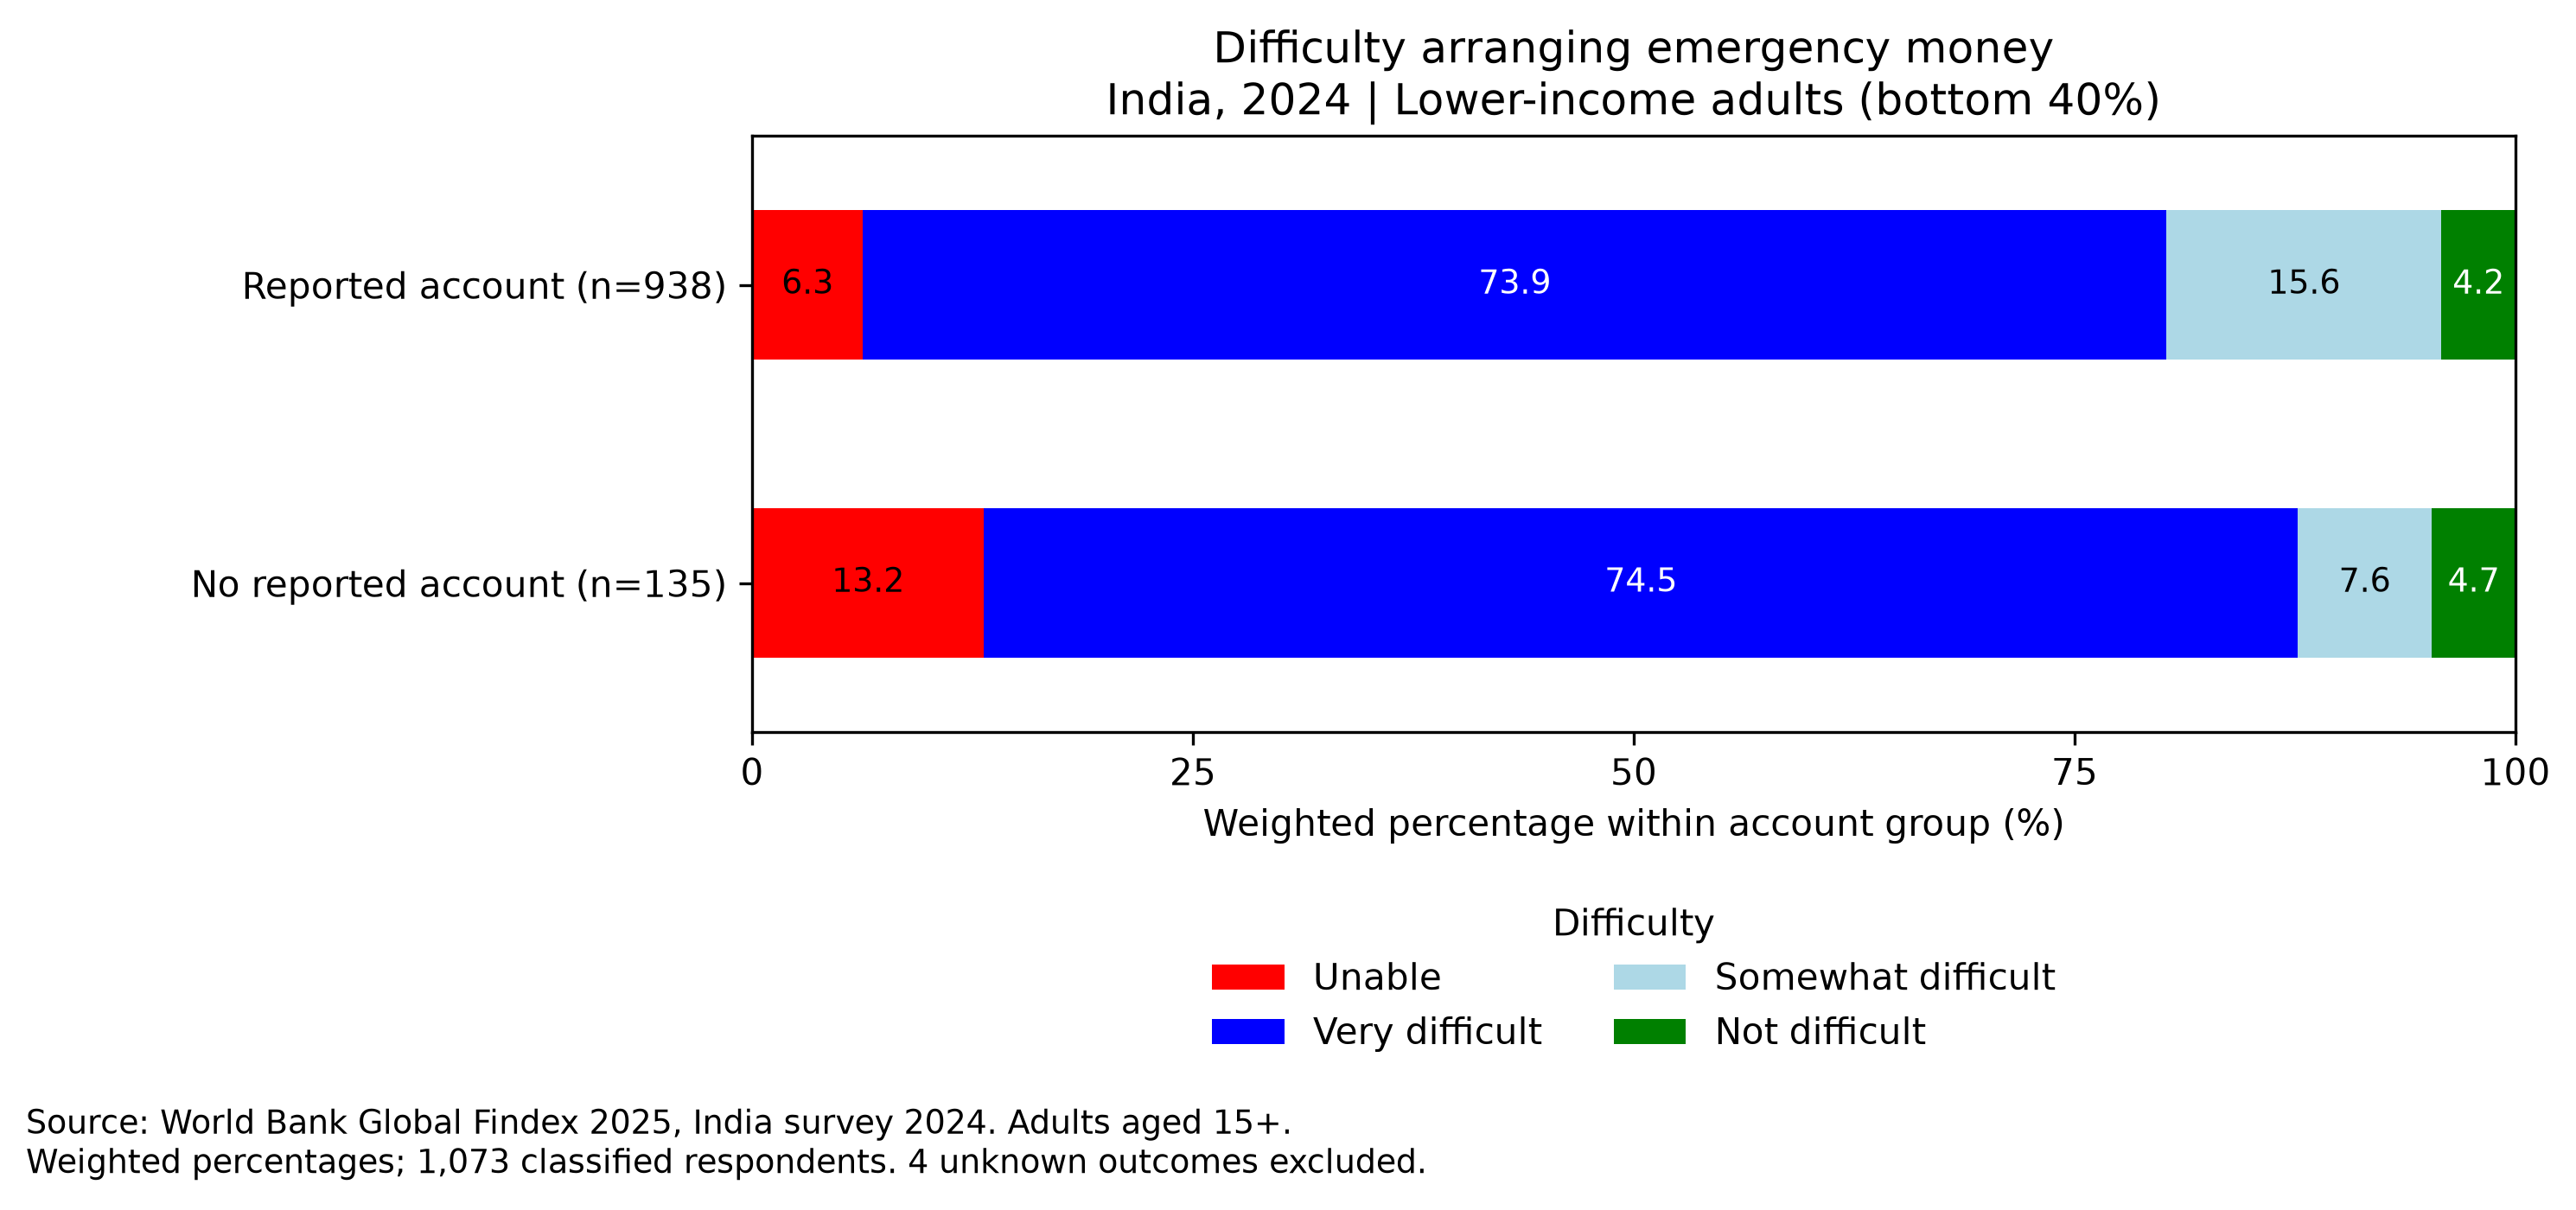

In [19]:
colors = ['red', 'blue', 'lightblue', 'green']
text_colors = ['black', 'white', 'black', 'white']
fig, ax = plt.subplots(figsize=(10, 5))
percentages.plot.barh(stacked=True, color=colors, ax=ax)
for bars, text_color in zip(ax.containers, text_colors):
    ax.bar_label(bars, fmt='%.1f', label_type='center', color=text_color, fontsize=9)
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel('Weighted percentage within account group (%)')
ax.set_ylabel('')
account_counts = known_difficulty['account_fin'].value_counts()
ax.set_yticks([0, 1], [f'No reported account (n={account_counts[0]})', f'Reported account (n={account_counts[1]})'])
ax.set_title('Difficulty arranging emergency money\nIndia, 2024 | Lower-income adults (bottom 40%)')
ax.legend(title='Difficulty', loc='upper center', bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False)
fig.subplots_adjust(left=.30, right=.98, top=.82, bottom=.36)
fig.text(.02, .02, 'Source: World Bank Global Findex 2025, India survey 2024. Adults aged 15+.\n'
         f'Weighted percentages; {len(known_difficulty):,} classified respondents. {len(low_income)-len(known_difficulty)} unknown outcomes excluded.', fontsize=9)
for suffix in ['png', 'pdf', 'svg']:
    fig.savefig(FIGURES / f'figure1_difficulty_distribution.{suffix}', dpi=300, bbox_inches='tight')
display(Image(filename=str(FIGURES / 'figure1_difficulty_distribution.png')))
plt.close(fig)


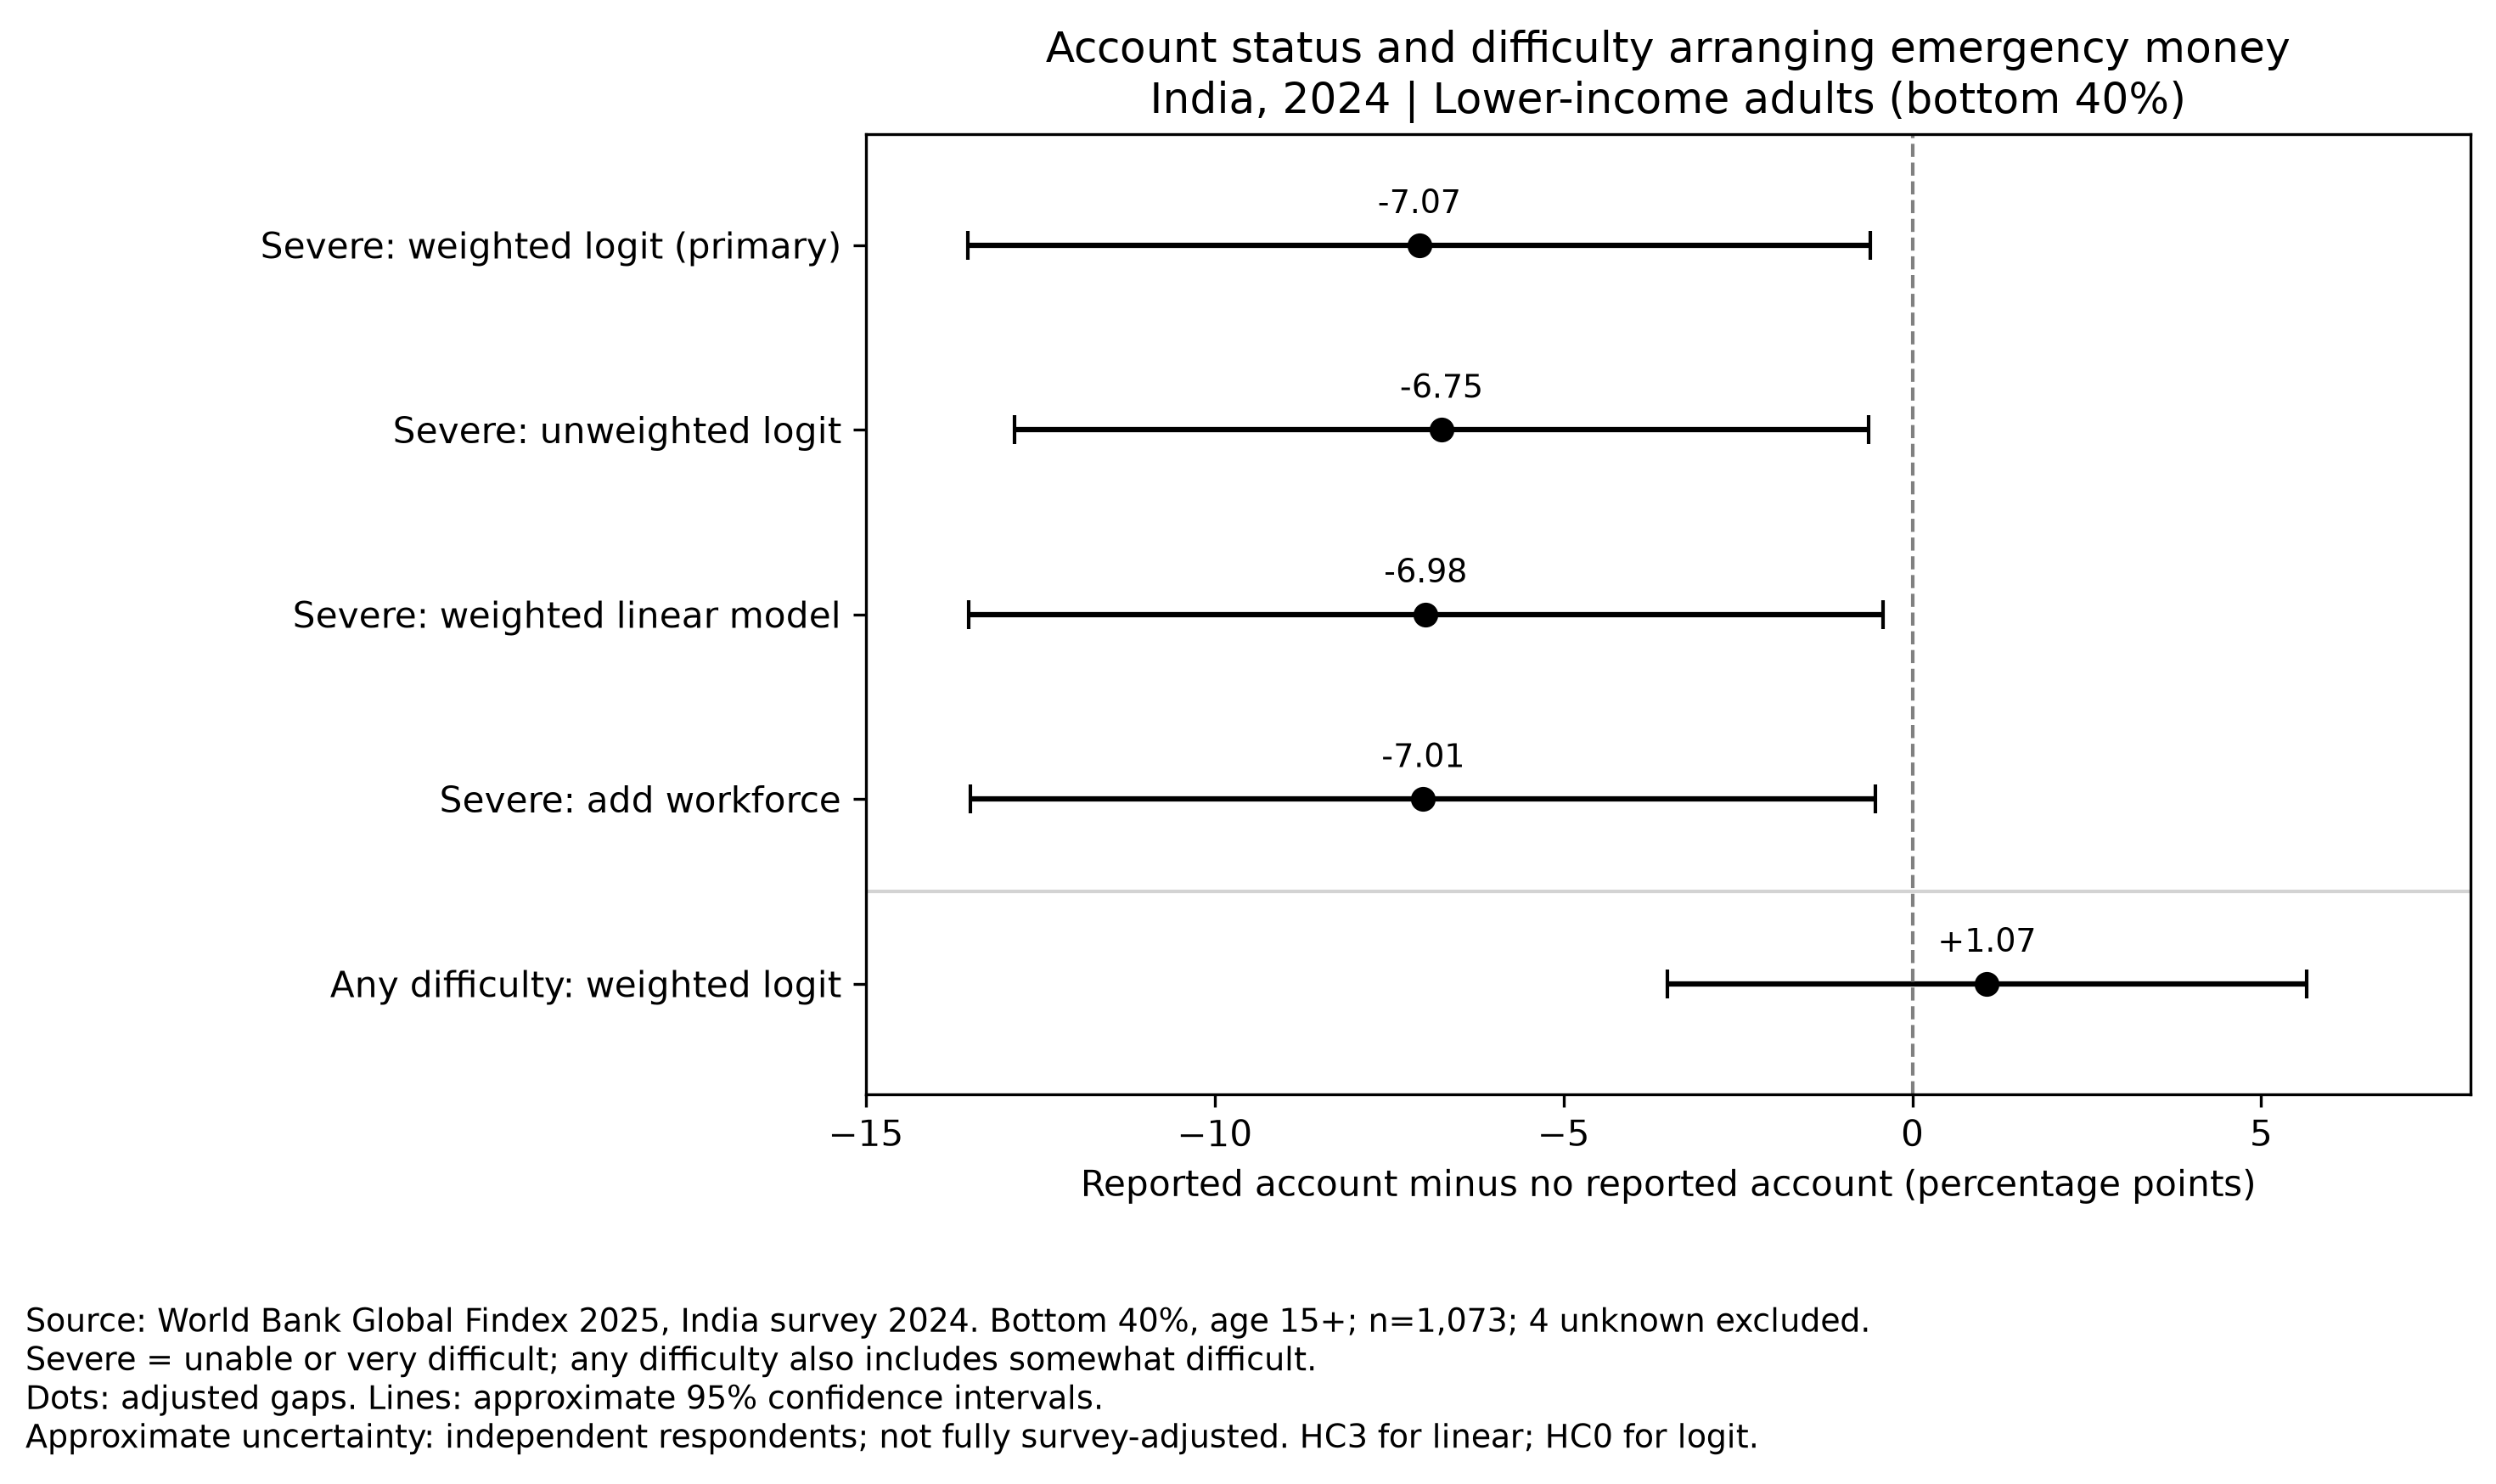

In [20]:
forest_order = ['M1_primary_weighted_logit', 'M1_unweighted_logit', 'M1_weighted_LPM', 'M2_add_workforce', 'M1_broader_any_difficulty']
model_names = ['Severe: weighted logit (primary)', 'Severe: unweighted logit', 'Severe: weighted linear model',
               'Severe: add workforce', 'Any difficulty: weighted logit']
model_results = model_checks.set_index('model').loc[forest_order, [
    'account1_minus_account0_gap_pp', 'approximate_95_ci_low_pp', 'approximate_95_ci_high_pp'
]].rename(columns={'account1_minus_account0_gap_pp': 'Gap', 'approximate_95_ci_low_pp': 'Lower', 'approximate_95_ci_high_pp': 'Upper'})
model_results['Model'] = model_names
fig2, ax2 = plt.subplots(figsize=(10, 6.5))
positions = range(len(model_results))
left_error = model_results['Gap'] - model_results['Lower']
right_error = model_results['Upper'] - model_results['Gap']
ax2.errorbar(model_results['Gap'], positions, xerr=[left_error, right_error], fmt='o',
             color='black', ecolor='black', markersize=6, capsize=4)
ax2.set_yticks(positions, model_results['Model'])
ax2.invert_yaxis()
ax2.margins(y=0.15)
ax2.axvline(0, color='gray', linestyle='--', linewidth=1)
ax2.axhline(3.5, color='lightgray', linewidth=1)
ax2.set_xlim(-15, 8)
ax2.set_xticks([-15, -10, -5, 0, 5])
ax2.set_xlabel('Reported account minus no reported account (percentage points)')
ax2.set_ylabel('')
ax2.set_title('Account status and difficulty arranging emergency money\nIndia, 2024 | Lower-income adults (bottom 40%)')
for position, estimate in enumerate(model_results['Gap']):
    ax2.annotate(f'{estimate:+.2f}', (estimate, position), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
fig2.subplots_adjust(left=0.35, right=0.98, top=0.82, bottom=0.24)
fig2.text(0.02, 0.02,
    'Source: World Bank Global Findex 2025, India survey 2024. Bottom 40%, age 15+; '
    f'n={len(model_data):,}; {len(low_income)-len(known_difficulty)} unknown excluded.\n'
    'Severe = unable or very difficult; any difficulty also includes somewhat difficult.\n'
    'Dots: adjusted gaps. Lines: approximate 95% confidence intervals.\n'
    'Approximate uncertainty: independent respondents; not fully survey-adjusted. HC3 for linear; HC0 for logit.',
    fontsize=9, va='bottom')
for suffix in ['png', 'pdf', 'svg']:
    fig2.savefig(FIGURES / f'figure2_robustness_intervals.{suffix}', dpi=300, bbox_inches='tight')
display(Image(filename=str(FIGURES / 'figure2_robustness_intervals.png')))
plt.close(fig2)


## Scope and sources

There are 135 classified respondents with no reported account and 938 reporting one. Unmeasured resources, financial knowledge, past shocks, and selection into accounts can affect both groups' reported difficulty. Financial circumstances can also influence account ownership. Demographic adjustment does not identify a causal account effect. Ownership does not measure account use, balances, or service quality, and the survey does not observe actual emergency outcomes or loan defaults.

Model form matters. Standardized predictions may extrapolate where the two groups have little covariate overlap. The uncertainty calculation cannot recover missing survey-design information. The results concern 2024 responses and the stated lower-income domain. [Data notes](data_notes.md) record geographic exclusions, the unexplained public-file/interview-count difference, exact source definitions, and method references.

Sources: [World Bank catalog](https://microdata.worldbank.org/catalog/7916); [account coding](https://microdata.worldbank.org/catalog/7916/variable/F1/V14?name=account_fin); [emergency source](https://microdata.worldbank.org/catalog/7916/variable/F1/V82?name=fin24) and [follow-up](https://microdata.worldbank.org/catalog/7916/variable/F1/V83?name=fin24a); [survey methodology](https://thedocs.worldbank.org/en/doc/be6615202d1f08a25855c8ac2d615122-0050012025/related/Survey-methodology.pdf); [published benchmarks and glossary](https://thedocs.worldbank.org/en/doc/be6615202d1f08a25855c8ac2d615122-0050012025/related/Little-Data-Book-2025-Web.pdf). Aggregate artifacts retain the input fingerprint and software versions.


In [21]:
provenance = {
    "source": {"catalog_url": CATALOG, "release": RELEASE, "survey_year": 2024,
               "input_filename": data_path.name, "input_sha256": input_sha256},
    "sample": {"public_use_n": len(df), "selected_n": len(low_income), "classified_n": len(known_difficulty),
               "primary_model_n": len(model_data), "workforce_model_n": int(workforce_available.sum())},
    "definitions": {"income": "Bottom two within-India household-income quintiles; adults age 15+",
                    "account0": "No / don't know / refused combined",
                    "severe": "Unable or very difficult", "broader": "Unable, very difficult, or somewhat difficult",
                    "emergency_question": "5% of local-currency GNI per capita within 30 days"},
    "inference": {"logit": "Original-weight independent-respondent HC0 sandwich; conditional delta normal interval",
                  "lpm": "statsmodels WLS HC3, normal interval; predictions not clipped",
                  "standardization": "Observed weighted covariate distribution held fixed; account 1 minus account 0",
                  "fully_design_adjusted_survey_inference": False},
    "lpm_diagnostics": {"minimum": float(lpm_fitted.min()), "maximum": float(lpm_fitted.max()),
                        "below_zero": int((lpm_fitted < 0).sum()), "above_one": int((lpm_fitted > 1).sum())},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "statsmodels": statsmodels.__version__, "matplotlib": matplotlib.__version__},
}
(METADATA / "provenance.json").write_text(json.dumps(provenance, indent=2, allow_nan=False) + "\n")
print("Saved aggregate tables, figure exports, and provenance under results/.")


Saved aggregate tables, figure exports, and provenance under results/.
